# 🪶 The Unbearable Lightness of Quantum Circuits

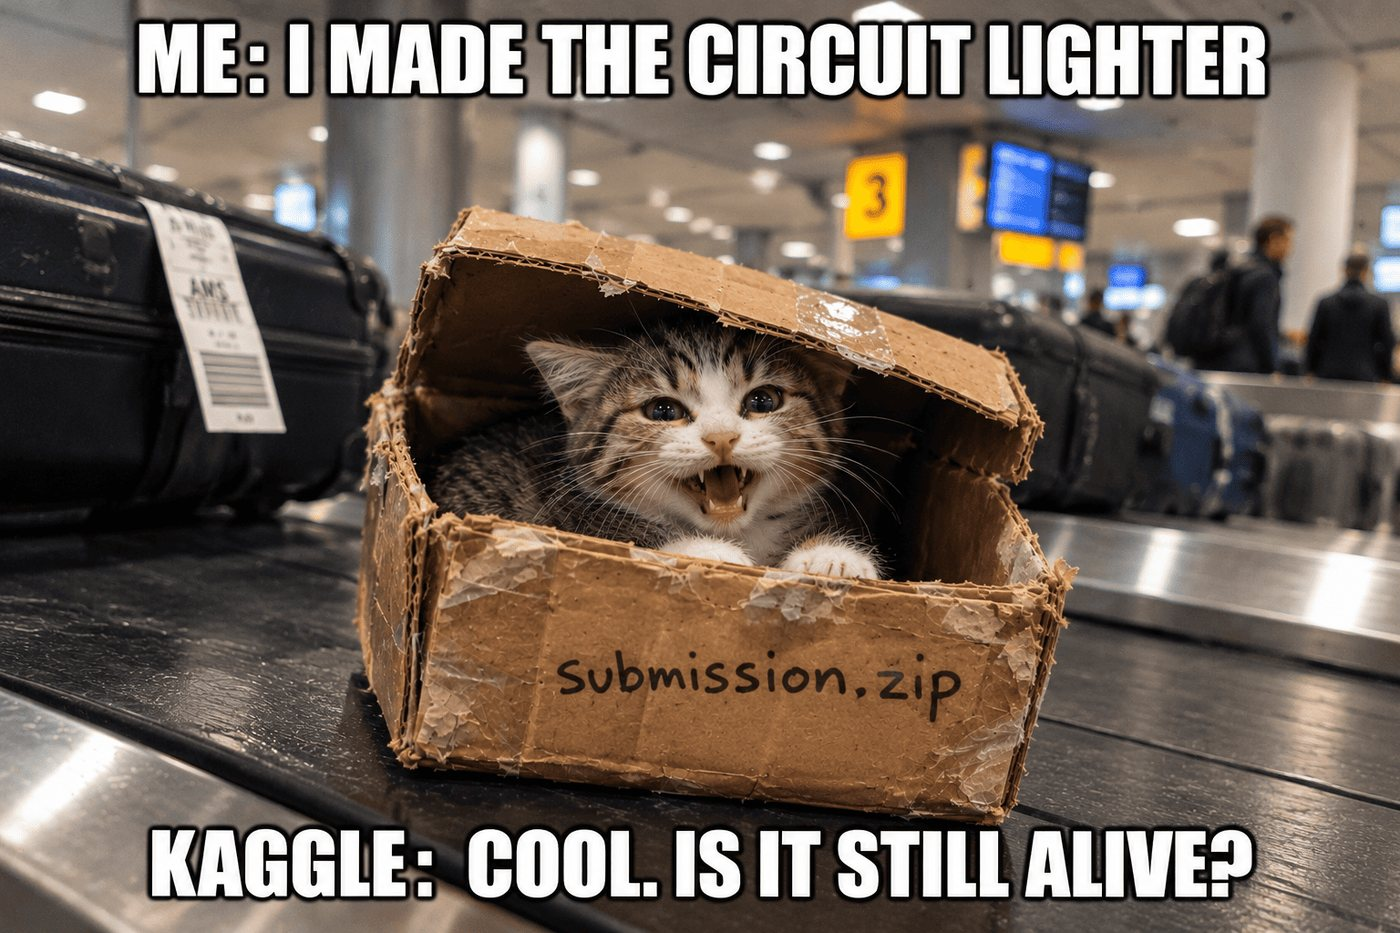

## A verifier-guided portfolio for three different workloads

The competition is three compiler problems with different notions of approximation, different resource
bottlenecks and different failure modes. A submission is a **portfolio**: one independently verified circuit family
per task, joined only by the geometric mean of the three ratios (reference loss / your loss).

> **This version.** Scan of 2026-11-06: the open frontier moved to about 24.94. It stacks the pi-gauge chemistry with $C=44$
> channels and recompiled loaders ($T=14{,}966$, $\lambda_{\mathrm{eff}}=46.893$), a 892-qubit DQI decoder with exact product reuse
> (about 395.4 thousand Toffolis per shot) and an invsqrt circuit at 97,747. This notebook pins that portfolio by SHA-256, re-runs the three official
> verifiers and polishes the continuous chemistry weights with its own constrained optimiser. The DQI decoder is approximate: of
> 102,400 verification shots an occasional one fails (+0.45 % DQI loss per failure), and which shots a file meets is fixed by its
> hash and the salt of the scored split, so each file draws its own failures on each split. An archive is written only if the
> complete official chemistry loss does not rise.

---

## 1. Where the loss comes from

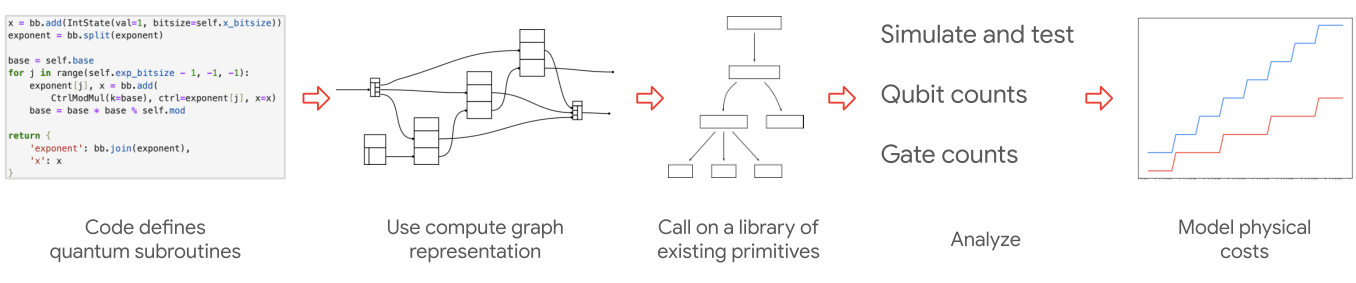

The figure is Figure 1 of Harrigan *et al.*, *Expressing and Analyzing Quantum Algorithms with Qualtran* (2024),
licensed [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

| Task | Loss | Reference |
|---|---|---:|
| `invsqrt` | $Q\,(N_{\mathrm{Toffoli}}+N_T/4)$, rotations priced by $0.56\log_2(1/\varepsilon)+5.3$ T each | 2,076,774 |
| `dqi` | $R(\varepsilon)\,Q^2\,T$, $R\ge 1.19126$ at zero failed shots | 2.444e13 |
| `dfthcsos` | $\lambda_{\mathrm{eff}}\,T\,Q$ with $\lambda_{\mathrm{eff}}=\sqrt{E_{\mathrm{gap}}(2\Lambda-E_{\mathrm{gap}})}$ | 3.356e9 |

For chemistry, $T=2\sum_k T_k^{\mathrm{ANGLE}}+T_{\mathrm{fixed}}$ ($T_{\mathrm{fixed}}=6{,}741$ at $C=45$, $6{,}662$ at $C=44$): fifteen loaders $k=0..14$ (each executed forward and in
reverse) plus outer and inner state preparation and the Givens network, which are fixed by the table shape. The
weights $W,\ H2_I$ set $\Lambda$ and the two reconstruction errors, which must stay below 20 mHa, with
$E_{\mathrm{gap}}>3.914898$.

## 2. How a loader is built

Loader $k$ XORs $\delta_k(a)=\mathrm{batch}_k(a)\oplus\mathrm{batch}_{k-1}(a)$ into five 8-bit word registers for
every address $a=16y+z<1220$ (35 independent output bits). Eighty "infrastructure" ANDs (69 monomials of the
77 $y$-values, 11 of the 16 $z$-values) make every function of $y$ alone and of $z$ alone free. Every other
Toffoli is a product $(A(y)\oplus a(z))(B(y)\oplus b(z))$ fanned out to a set of outputs. Modulo the free
functions it contributes the rank-2 matrix $A\otimes b+B\otimes a$. A parameter count (an estimate, not a
proof) says that 35 generic outputs need about 187 such products and that each *linear dependency* between
outputs removes about 4.5 of them. The published write-up reports exactly this kind of move: word edits of
tiny weight cost that create dependencies between outputs and lower the product count.

The loaders themselves are not touched here. Their words are fixed by the table, so only the weights can
still move.

## 3. The step of this notebook

With the words fixed, the native weights $W_n=H2_I-\sum_b w$ enter only through $h_1'$ (hence $\mathrm{error}_1$ and
the eigenvalues), $\Lambda$ and $E_{\mathrm{gap}}$; $\mathrm{error}_2$ does not depend on them. So
$\lambda_{\mathrm{eff}}$ is minimised over 360 numbers under $\mathrm{error}_1\le 0.02$ and
$E_{\mathrm{gap}}>3.914898$. The objective has an analytic gradient
($\partial\lambda_j/\partial W_{n,rc}=-v_j^{	op}X_{rc}v_j$ for the eigenpairs of $h_1'$), so SLSQP with exact
Jacobians converges in seconds, to a point where $E_{\mathrm{gap}}$ sits on its floor; passes are repeated until one
gains less than $10^{-9}$. The official verifier is the final judge.

H3 then frees the coefficient tensor too. With the words fixed, $h_1'=M_0-\sum_{rb}a_{rb}u_{rb}u_{rb}^{	op}$ with
$a_{rb}=\sum_c W_{n,rc}w_{rbc}$, so $\partial\lambda_j/\partial w_{rbc}=-W_{n,rc}(u_{rb}\cdot v_j)^2$, and
$\mathrm{error}_2$ comes from the reduced Gram model (thin QR of the $n^2	imes RB$ matrix of vector products).
An augmented Lagrangian over $(w,W_n)$ minimises $\lambda_{\mathrm{eff}}$ under $\mathrm{error}_2\le 20$ mHa and the
$E_{\mathrm{gap}}$ floor; H2 is run again on its result.


In [ ]:
import os
os.makedirs('/tmp/qcc_tools', exist_ok=True)

In [ ]:
%%writefile /tmp/qcc_tools/gauge_descent.py
"""Exact pairwise orthogonal-gauge descent of the DFTHC coefficient channels.

Setting. For each group rho the augmented coefficient matrix is
A_rho = [w_rho ; w_B_rho] with shape (B + 1, C): the B rows of ``W`` and the
row ``H2_I``. Rotating two channel columns (i, j) of A_rho by the same angle
leaves A_rho A_rho^T unchanged, so sum_c X_c (x) X_c, sum_c W_c X_c and
sum_c W_c^2 keep their values: both reconstruction errors and the SOS gap are
untouched. Only the L1 term of the LCU one-norm moves:

    Lambda_L1 = 1/4 * sum_{rho, c} ( sum_rows |A_rho[:, c]| )^2 .

For a pair of columns (x, y) the rotated pair is (c x + s y, c y - s x). With
the sign patterns fixed, the objective is A + B cos 2t + C sin 2t, so every
piece between two sign changes has a closed-form minimum. The sign changes
are the roots of x' = 0 and y' = 0 elements; the global minimum on
[-radius, radius] is the best of all piece endpoints and interior stationary
points.

Usage: python tools/gauge_descent.py in.npz out.npz [--sweeps N] [--radius R]
"""

import argparse
import json
import time
from pathlib import Path

import numpy as np


def l1_objective(a):
    return float(0.25 * np.square(np.abs(a).sum(axis=-2)).sum())


def best_angle(x, y, radius):
    """Return (theta, value) minimising |x'|_1^2 + |y'|_1^2 on [-radius, radius]."""
    roots = np.concatenate([np.arctan2(-x, y), np.arctan2(y, x)])
    roots = (roots + np.pi / 2) % np.pi - np.pi / 2
    inside = roots[(roots > -radius) & (roots < radius)]
    cuts = np.unique(np.r_[-radius, 0.0, inside, radius])
    mids = (cuts[1:] + cuts[:-1]) / 2
    c, s = np.cos(mids)[:, None], np.sin(mids)[:, None]
    sx, sy = np.sign(c * x + s * y), np.sign(c * y - s * x)
    p, q = sx @ x, sx @ y          # |x'|_1 = c p + s q
    r, u = sy @ y, -(sy @ x)       # |y'|_1 = c r + s u
    aa, bb, cc = p * p + r * r, q * q + u * u, p * q + r * u
    # f = (aa + bb)/2 + (aa - bb)/2 cos 2t + cc sin 2t, minimum at 2t = atan2(-cc, -(aa - bb)/2)
    stationary = 0.5 * np.arctan2(-cc, -(aa - bb) / 2)
    candidates = [cuts]
    for shift in (-np.pi, 0.0, np.pi):
        pts = stationary + shift
        keep = (pts > cuts[:-1]) & (pts < cuts[1:])
        candidates.append(pts[keep])
    theta = np.concatenate(candidates)
    c, s = np.cos(theta)[:, None], np.sin(theta)[:, None]
    values = np.square(np.abs(c * x + s * y).sum(1)) + np.square(np.abs(c * y - s * x).sum(1))
    k = int(np.argmin(values))
    return float(theta[k]), float(values[k])


def descend(source, output, sweeps, radius, seed):
    with np.load(source, allow_pickle=False) as z:
        data = {k: np.array(z[k]) for k in z.files}
    a0 = np.concatenate([data["W"], data["H2_I"][:, None, :]], axis=1)   # (R, B+1, C)
    a = a0.copy()
    groups, _, channels = a.shape
    gram0 = a0 @ a0.transpose(0, 2, 1)
    rng = np.random.default_rng(seed)
    pairs = [(g, i, j) for g in range(groups) for i in range(channels) for j in range(i + 1, channels)]
    history, t0 = [], time.time()
    for sweep in range(sweeps):
        accepted = 0
        for index in rng.permutation(len(pairs)):
            g, i, j = pairs[index]
            x, y = a[g, :, i].copy(), a[g, :, j].copy()
            before = np.abs(x).sum() ** 2 + np.abs(y).sum() ** 2
            theta, value = best_angle(x, y, radius)
            if value < before - 1e-13:
                c, s = np.cos(theta), np.sin(theta)
                a[g, :, i], a[g, :, j] = c * x + s * y, c * y - s * x
                accepted += 1
        record = dict(sweep=sweep, objective=l1_objective(a), accepted=accepted,
                      seconds=round(time.time() - t0, 1))
        history.append(record)
        print(json.dumps(record), flush=True)
        if accepted == 0:
            break
    defect = float(np.max(np.abs(a @ a.transpose(0, 2, 1) - gram0)))
    assert defect < 1e-9, defect
    data["W"], data["H2_I"] = a[:, :-1, :], a[:, -1, :]
    if "offset_W" in data:
        data["offset_W"] = data["H2_I"] - data["W"].sum(axis=1)
    Path(output).parent.mkdir(parents=True, exist_ok=True)
    np.savez(output, **data)
    report = dict(before=l1_objective(a0), after=l1_objective(a), gram_defect=defect,
                  seed=seed, radius=radius, history=history)
    Path(output).with_suffix(".json").write_text(json.dumps(report, indent=2))
    return report


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("source")
    ap.add_argument("output")
    ap.add_argument("--sweeps", type=int, default=5)
    ap.add_argument("--radius", type=float, default=0.03)
    ap.add_argument("--seed", type=int, default=20261103)
    args = ap.parse_args()
    print(json.dumps(descend(args.source, args.output, args.sweeps, args.radius, args.seed))[:400])


In [ ]:
%%writefile /tmp/qcc_tools/native_w_search.py
"""Constrained search over the native one-body-absorption weights W (R x C).

Fixed: angle words, tree, the coefficient tensor ``w`` (npz key ``W``). With
``w`` and the decoded vectors fixed, X^(rho c), the two-body residual
``error_2`` and the Gram tensor do not depend on the native weights
``Wn = H2_I - sum_b w``. Wn enters only through

    h1' = M0 - sum_rc Wn_rc X_rc        (eigenvalues l_j, error_1)
    Lambda = sum_j |l_j| + 1/4 sum_rc (|w|_1 + |Wn + sum_b w|)^2
    E_gap  = E_upper - (ecore - eta beta - (sum|l_j| - sum l_j) - 1/2 sum Wn^2)
    lambda_eff = sqrt(E_gap (2 Lambda - E_gap)),

so lambda_eff can be minimised over the 360 numbers Wn with milliseconds per
evaluation, subject to error_1 <= 0.02 and E_gap > 3.914898. error_2 is
unchanged by construction; the official verifier remains the final judge.

Usage: python tools/native_w_search.py in.npz out.npz --verifiers <dir with dfthcsos>
       [--stubs <dir with a kickmix stub>] [--iters N]
"""

import argparse
import json
import sys
import time
from pathlib import Path

import numpy as np
from scipy.optimize import linear_sum_assignment, minimize

ERR1_LIMIT = 0.020
GAP_FLOOR = 3.914898


class Evaluator:
    def __init__(self, factor, dfthcsos_verify, dfthc_math):
        self.inputs = dfthcsos_verify.load_inputs(factor)
        inp = self.inputs
        words = np.asarray(factor["angle_words"])
        brot = int(factor.get("brot", 8))
        edges = np.asarray(factor["tree_edges"])
        u_all = dfthc_math.reconstruct_u_vectors(words / (1 << (brot - 1)), edges)
        u_all = u_all / np.linalg.norm(u_all, axis=1, keepdims=True)
        one_body, u_b = dfthc_math.split_u_vectors(u_all, inp.w)
        x = dfthc_math.reconstruct_x(u_b, inp.w)
        self.x = np.tril(x) + np.swapaxes(np.tril(x, k=-1), -1, -2)
        ref = inp.ref
        self.eta = ref["electrons"]
        self.ecore = ref["ecore"]
        self.e_upper = inp.energy_upper
        self.beta = inp.beta_1
        h1_thc = ref["oei"] - 0.5 * np.einsum("prrq->pq", ref["tei"])
        self.m0 = h1_thc - 0.5 * self.eta * inp.S + self.beta * np.eye(h1_thc.shape[0])
        self.one_body = np.asarray(one_body, float)
        self.w = inp.w
        self.w_l1 = np.abs(inp.w).sum(axis=1)          # (R, C)
        self.w_sum = inp.w.sum(axis=1)                 # (R, C)
        self.native0 = inp.W.copy()
        self._cache = {}

    def metrics(self, z):
        key = z.tobytes()
        hit = self._cache.get(key)
        if hit is not None:
            return hit
        z2 = z.reshape(self.native0.shape)
        h1p = self.m0 - np.einsum("rc,rcpq->pq", z2, self.x, optimize=True)
        ev, vec = np.linalg.eigh(h1p)
        rows, cols = linear_sum_assignment(-np.abs(self.one_body @ vec))
        matched = np.empty_like(ev)
        matched[rows] = ev[cols]
        recon = np.einsum("j,jp,jq->pq", matched, self.one_body, self.one_body, optimize=True)
        err1 = float(np.linalg.norm(recon - h1p))
        lam1 = float(np.abs(ev).sum())
        lam2 = float(0.25 * np.square(self.w_l1 + np.abs(z2 + self.w_sum)).sum())
        big = lam1 + lam2
        e_sos = self.ecore - self.eta * self.beta - (lam1 - ev.sum()) - 0.5 * float(np.square(z2).sum())
        gap = self.e_upper - e_sos
        rad = gap * (2 * big - gap)
        out = dict(err1=err1, Lambda=big, gap=gap,
                   lam_eff=float(np.sqrt(rad)) if rad > 0 else float("inf"))
        if len(self._cache) > 5000:
            self._cache.clear()
        self._cache[key] = out
        return out


def run(source, output, verifiers, stubs, iters, err1_margin, gap_margin):
    if stubs:
        sys.path.insert(0, str(stubs))
    sys.path.insert(0, str(verifiers))
    from dfthcsos import verify as dv
    from dfthcsos.scoreinfra import dfthc_math as dm

    with np.load(source, allow_pickle=False) as z:
        factor = {k: np.array(z[k]) for k in z.files}
    ev = Evaluator(factor, dv, dm)
    z0 = ev.native0.ravel().copy()
    m0 = ev.metrics(z0)
    print("start", json.dumps(m0), flush=True)

    scale = max(1e-3, float(np.abs(z0).mean()))
    fun = lambda t: ev.metrics(t * scale)["lam_eff"]
    cons = [
        {"type": "ineq", "fun": lambda t: (ERR1_LIMIT - err1_margin) - ev.metrics(t * scale)["err1"]},
        {"type": "ineq", "fun": lambda t: ev.metrics(t * scale)["gap"] - (GAP_FLOOR + gap_margin)},
    ]
    t0 = time.time()
    res = minimize(fun, z0 / scale, method="SLSQP", constraints=cons,
                   options=dict(maxiter=iters, ftol=1e-13, eps=1e-7, disp=False))
    z1 = res.x * scale
    m1 = ev.metrics(z1)
    print("end", json.dumps(m1), "seconds", round(time.time() - t0, 1), "status", res.status,
          res.message, flush=True)
    ok = (m1["err1"] <= ERR1_LIMIT - err1_margin * 0.5 and m1["gap"] > GAP_FLOOR + gap_margin * 0.5
          and m1["lam_eff"] < m0["lam_eff"])
    out = dict(factor)
    if ok:
        out["H2_I"] = z1.reshape(ev.native0.shape) + ev.w_sum
        if "offset_W" in out:
            out["offset_W"] = z1.reshape(ev.native0.shape)
    Path(output).parent.mkdir(parents=True, exist_ok=True)
    np.savez(output, **out)
    report = dict(start=m0, end=m1, accepted=bool(ok),
                  rel_gain=(m0["lam_eff"] - m1["lam_eff"]) / m0["lam_eff"])
    Path(output).with_suffix(".json").write_text(json.dumps(report, indent=2))
    print(json.dumps(report))
    return report


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("source")
    ap.add_argument("output")
    ap.add_argument("--verifiers", required=True)
    ap.add_argument("--stubs")
    ap.add_argument("--iters", type=int, default=60)
    ap.add_argument("--err1-margin", type=float, default=1e-6)
    ap.add_argument("--gap-margin", type=float, default=3e-7)
    a = ap.parse_args()
    run(a.source, a.output, Path(a.verifiers), Path(a.stubs) if a.stubs else None,
        a.iters, a.err1_margin, a.gap_margin)


In [ ]:
%%writefile /tmp/qcc_tools/native_w_grad.py
"""Gradient-based minimisation of lambda_eff over the native weights Wn (R x C).

Same model as ``native_w_search.py`` (words, tree, ``w`` fixed; Wn enters only through h1', Lambda and E_gap), but with
the analytic gradient of lambda_eff, so a quasi-Newton step costs one eigendecomposition instead of 361 finite-difference
evaluations. error_1 and E_gap are kept inside their limits by a penalty and by a final line search back towards the
start point; the official verifier remains the judge.

    d ev_j / d Wn_rc            = - v_j^T X_rc v_j
    Lambda                      = sum|ev| + 1/4 sum (|w|_1 + |Wn + sum w|)^2
    E_gap                       = E_upper - (ecore - eta beta - sum(|ev| - ev) - 1/2 sum Wn^2)
    lambda_eff                  = sqrt(E_gap (2 Lambda - E_gap))

Usage: python tools/native_w_grad.py in.npz out.npz --verifiers <dir with dfthcsos> [--stubs <dir>] [--iters N]
"""

import argparse
import json
import sys
import time
from pathlib import Path

import numpy as np
from scipy.optimize import linear_sum_assignment, minimize

sys.path.insert(0, str(Path(__file__).resolve().parent))
from native_w_search import ERR1_LIMIT, GAP_FLOOR, Evaluator  # noqa: E402


def err1_gamma(h1p, one_body):
    """error_1 = ||recon - h1'||_F and Gamma with d(error_1^2) = <Gamma, dh1'> (matching held fixed)."""
    lam, vec = np.linalg.eigh(h1p)
    rows, cols = linear_sum_assignment(-np.abs(one_body @ vec))
    matched = np.empty_like(lam)
    matched[rows] = lam[cols]
    recon = np.einsum("j,jp,jq->pq", matched, one_body, one_body, optimize=True)
    d = recon - h1p
    err1 = float(np.linalg.norm(d))
    c = np.einsum("jp,pq,jq->j", one_body, d, one_body, optimize=True)      # <D, O_j>
    v = vec[:, cols]                                                       # eigenvector matched to one_body row j
    gamma = -2.0 * d + 2.0 * np.einsum("j,pj,qj->pq", c, v, v, optimize=True)
    return err1, gamma


def value_grad(ev, z):
    z2 = z.reshape(ev.native0.shape)
    h1p = ev.m0 - np.einsum("rc,rcpq->pq", z2, ev.x, optimize=True)
    lam, vec = np.linalg.eigh(h1p)
    # d lam_j / d z_rc = - v_j^T X_rc v_j
    xv = np.einsum("rcpq,qj->rcpj", ev.x, vec, optimize=True)
    dlam = -np.einsum("pj,rcpj->rcj", vec, xv, optimize=True)
    sg = np.sign(lam)
    lam1 = float(np.abs(lam).sum())
    d_lam1 = np.einsum("rcj,j->rc", dlam, sg)
    t = ev.w_l1 + np.abs(z2 + ev.w_sum)
    lam2 = float(0.25 * np.square(t).sum())
    d_lam2 = 0.5 * t * np.sign(z2 + ev.w_sum)
    big = lam1 + lam2
    d_big = d_lam1 + d_lam2
    neg = float((np.abs(lam) - lam).sum())
    d_neg = np.einsum("rcj,j->rc", dlam, sg - 1.0)
    e_sos = ev.ecore - ev.eta * ev.beta - neg - 0.5 * float(np.square(z2).sum())
    d_e_sos = -d_neg - z2
    gap = ev.e_upper - e_sos
    d_gap = -d_e_sos
    rad = gap * (2 * big - gap)
    lam_eff = float(np.sqrt(rad))
    d_lam_eff = (d_gap * (big - gap) + gap * d_big) / lam_eff
    return lam_eff, d_lam_eff.ravel(), gap, d_gap.ravel()


def run(source, output, verifiers, stubs, iters, err1_margin=1e-6, gap_margin=2e-8):
    if stubs:
        sys.path.insert(0, str(stubs))
    sys.path.insert(0, str(verifiers))
    from dfthcsos import verify as dv
    from dfthcsos.scoreinfra import dfthc_math as dm

    with np.load(source, allow_pickle=False) as zf:
        factor = {k: np.array(zf[k]) for k in zf.files}
    ev = Evaluator(factor, dv, dm)
    z0 = ev.native0.ravel().copy()
    m0 = ev.metrics(z0)
    print("start", json.dumps(m0), flush=True)
    scale = max(1e-3, float(np.abs(z0).mean()))
    err_cap, gap_cap = ERR1_LIMIT - err1_margin, GAP_FLOOR + gap_margin

    cache = {}

    def vg(t):
        key = t.tobytes()
        if key not in cache:
            if len(cache) > 50:
                cache.clear()
            cache[key] = value_grad(ev, t * scale)
        return cache[key]

    cache1 = {}

    def e1(t):
        key = t.tobytes()
        if key not in cache1:
            if len(cache1) > 50:
                cache1.clear()
            z2 = (t * scale).reshape(ev.native0.shape)
            h1p = ev.m0 - np.einsum("rc,rcpq->pq", z2, ev.x, optimize=True)
            err1, gamma = err1_gamma(h1p, ev.one_body)
            g = -np.einsum("rcpq,pq->rc", ev.x, gamma, optimize=True) / (2 * err1)
            cache1[key] = (err1, g.ravel() * scale)
        return cache1[key]

    cons = [{"type": "ineq", "fun": lambda t: vg(t)[2] - gap_cap, "jac": lambda t: vg(t)[3] * scale},
            {"type": "ineq", "fun": lambda t: err_cap - e1(t)[0], "jac": lambda t: -e1(t)[1]}]
    t0 = time.time()
    res = minimize(lambda t: vg(t)[0], z0 / scale, jac=lambda t: vg(t)[1] * scale, method="SLSQP", constraints=cons,
                   options=dict(maxiter=iters, ftol=1e-15))
    z1 = res.x * scale
    # the unconstrained optimum may break error_1 / E_gap: walk back towards the start until both hold
    best, frac = z0, 0.0
    for f in (1.0, 0.75, 0.5, 0.35, 0.25, 0.15, 0.1, 0.05, 0.02, 0.01):
        z = z0 + f * (z1 - z0)
        m = ev.metrics(z)
        if m["err1"] <= err_cap and m["gap"] >= gap_cap and m["lam_eff"] < ev.metrics(best)["lam_eff"]:
            best, frac = z, f
            break
    m1 = ev.metrics(best)
    print("end", json.dumps(m1), "step fraction", frac, "seconds", round(time.time() - t0, 1), "status", res.status,
          res.message, "nit", res.nit, flush=True)
    ok = m1["lam_eff"] < m0["lam_eff"] and frac > 0
    out = dict(factor)
    if ok:
        out["H2_I"] = best.reshape(ev.native0.shape) + ev.w_sum
        if "offset_W" in out:
            out["offset_W"] = best.reshape(ev.native0.shape)
    Path(output).parent.mkdir(parents=True, exist_ok=True)
    np.savez(output, **out)
    report = dict(start=m0, end=m1, accepted=bool(ok), step_fraction=frac,
                  rel_gain=(m0["lam_eff"] - m1["lam_eff"]) / m0["lam_eff"])
    Path(output).with_suffix(".json").write_text(json.dumps(report, indent=2))
    print(json.dumps(report))
    return report


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("source")
    ap.add_argument("output")
    ap.add_argument("--verifiers", required=True)
    ap.add_argument("--stubs")
    ap.add_argument("--iters", type=int, default=300)
    args = ap.parse_args()
    run(args.source, args.output, args.verifiers, args.stubs, args.iters)


In [ ]:
%%writefile /tmp/qcc_tools/chem_rank_lab.py
"""Reduced model of the two-body error for fixed angle words and a chosen channel count C.

For fixed decoded vectors u_b (rows of the angle-word table) the two-body
residual depends on the weights only through the per-group Gram matrices
G_rho = w_rho w_rho^T (B x B, w_rho of shape B x C):

    sum_{rho,c} X_rc (x) X_rc = M blockdiag(G_rho) M^T,    M[(pq), (rho,b)] = u_b[p] u_b[q].

With the thin QR M = Q R the error splits into a constant (the part of the
target outside range(M)) and || R blockdiag(G) R^T - Q^T T Q ||_F, a problem of
size R*B = 1287. This module builds that model, checks it against the
official ``error_2`` and minimises it over w of rank C (C=40 is what the
circuits and cost model currently use; every channel removed lowers T*Q by
0.56% without touching a circuit, because the circuits load only the vectors).

Usage (host, kickmix stub on the path):
    python chem_rank_lab.py in.npz --verifiers DIR --stubs DIR [--ranks 40 39 38]
"""

import argparse
import sys
import time

import numpy as np
from scipy.optimize import minimize


class Reduced:
    def __init__(self, factor, dv, dm):
        self.inp = dv.load_inputs(factor)
        inp = self.inp
        words, edges, brot = np.asarray(factor["angle_words"]), np.asarray(factor["tree_edges"]), int(factor.get("brot", 8))
        u = dm.reconstruct_u_vectors(words / (1 << (brot - 1)), edges)
        u = u / np.linalg.norm(u, axis=1, keepdims=True)
        n = inp.num_orbitals
        R_, B_, C_ = inp.w.shape
        self.R, self.B, self.n = R_, B_, n
        ub = u[n:].reshape(R_, B_, n)
        self.u_one = u[:n]
        M = np.einsum("tbp,tbq->pqtb", ub, ub).reshape(n * n, R_ * B_)
        t0 = time.time()
        Q, Rm = np.linalg.qr(M)
        self.Rm = Rm
        tei = np.asarray(inp.ref["tei"], float).reshape(n * n, n * n)
        S = np.asarray(inp.S, float)
        eye = np.eye(n).ravel()
        s_vec = S.ravel()
        T = tei + 0.5 * (np.outer(s_vec, eye) + np.outer(eye, s_vec))
        self.Tt = Q.T @ T @ Q
        # M G M^T lies in range(M) x range(M), so ||M G M^T - T||^2 = ||R G R^T - Q^T T Q||^2 + ||T||^2 - ||Q^T T Q||^2.
        self.const = float(np.sum(T * T) - np.sum(self.Tt * self.Tt))
        self.setup_seconds = time.time() - t0

    def grams(self, w):
        return np.einsum("rbc,rdc->rbd", w, w)

    def error2_sq(self, w):
        G = self.grams(w)
        Gb = np.zeros((self.R * self.B,) * 2)
        for r in range(self.R):
            Gb[r * self.B:(r + 1) * self.B, r * self.B:(r + 1) * self.B] = G[r]
        Y = self.Rm @ Gb @ self.Rm.T - self.Tt
        return float(np.sum(Y * Y)) + self.const, Y

    def value_grad(self, w):
        val, Y = self.error2_sq(w)
        H = self.Rm.T @ Y @ self.Rm              # d/dG of 1/2 ... times 2 below
        grad = np.empty_like(w)
        for r in range(self.R):
            Hr = H[r * self.B:(r + 1) * self.B, r * self.B:(r + 1) * self.B]
            grad[r] = 4.0 * Hr @ w[r]            # d||.||^2/dw = 2*2*H w (H symmetric)
        return val, grad


def truncate(w, h, c):
    a = np.concatenate([w, h[:, None, :]], axis=1)
    wt = np.zeros((a.shape[0], w.shape[1], c))
    ht = np.zeros((a.shape[0], c))
    for r in range(a.shape[0]):
        u_, s, vt = np.linalg.svd(a[r], full_matrices=False)
        ar = u_[:, :c] * s[:c]
        wt[r], ht[r] = ar[:w.shape[1]], ar[w.shape[1]]
    return wt, ht


def min_error(red, w0, iters=150):
    """Minimise the reduced two-body error over w of the shape of ``w0``; returns (start, end) in Hartree."""
    v0, _ = red.error2_sq(w0)
    res = minimize(lambda x: red.value_grad(x.reshape(w0.shape))[0], w0.ravel(),
                   jac=lambda x: red.value_grad(x.reshape(w0.shape))[1].ravel(),
                   method="L-BFGS-B", options=dict(maxiter=iters, maxcor=30))
    return float(np.sqrt(v0)), float(np.sqrt(res.fun)), int(res.nit)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("source")
    ap.add_argument("--verifiers", required=True)
    ap.add_argument("--stubs")
    ap.add_argument("--ranks", nargs="+", type=int, default=[40, 39, 38])
    ap.add_argument("--iters", type=int, default=300)
    a = ap.parse_args()
    if a.stubs:
        sys.path.insert(0, a.stubs)
    sys.path.insert(0, a.verifiers)
    from dfthcsos import verify as dv
    from dfthcsos.scoreinfra import dfthc_math as dm

    with np.load(a.source, allow_pickle=False) as z:
        f = {k: np.array(z[k]) for k in z.files}
    red = Reduced(f, dv, dm)
    print("setup %.1f s" % red.setup_seconds)
    val, _ = red.error2_sq(f["W"])
    print("current error_2 (reduced model): %.9f   official 0.02" % np.sqrt(val))
    for c in a.ranks:
        w0, h0 = truncate(f["W"], f["H2_I"], c)
        v0, _ = red.error2_sq(w0)
        t0 = time.time()
        res = minimize(lambda x: red.value_grad(x.reshape(w0.shape))[0],
                       w0.ravel(), jac=lambda x: red.value_grad(x.reshape(w0.shape))[1].ravel(),
                       method="L-BFGS-B", options=dict(maxiter=a.iters, maxcor=30))
        print(f"rank {c}: start error_2 {np.sqrt(v0)*1e3:.4f} mHa -> minimised {np.sqrt(res.fun)*1e3:.4f} mHa "
              f"({res.nit} it, {time.time()-t0:.0f} s)", flush=True)


if __name__ == "__main__":
    main()


In [ ]:
%%writefile /tmp/qcc_tools/joint_refit.py
"""Joint refit of the DF-THC weights w (R x B x C) and native weights Wn (R x C) with analytic gradients.

Fixed: angle words (hence the vectors u_b), tree, circuits. Free: w and Wn, with H2_I = Wn + sum_b w.

    X_rc          = sum_b w_rbc u_rb u_rb^T                      (linear in w)
    h1'           = M0 - sum_rc Wn_rc X_rc = M0 - sum_rb a_rb u_rb u_rb^T,  a_rb = sum_c Wn_rc w_rbc
    d ev_j / d w_rbc = - Wn_rc (u_rb . v_j)^2,   d ev_j / d Wn_rc = - sum_b w_rbc (u_rb . v_j)^2
    Lambda        = sum|ev| + 1/4 sum_rc (sum_b |w_rbc| + |Wn_rc + sum_b w_rbc|)^2
    E_gap         = E_upper - (ecore - eta beta - sum(|ev| - ev) - 1/2 sum Wn^2)
    lambda_eff    = sqrt(E_gap (2 Lambda - E_gap))
    error_2^2     = || R blockdiag(w w^T) R^T - Q^T T Q ||^2 + const        (chem_rank_lab.Reduced)

Minimise lambda_eff subject to error_2 <= cap2 and E_gap >= floor by an augmented Lagrangian with L-BFGS-B inner
solves; error_1 is checked afterwards (walk back towards the start if it is violated). The official verifier is the judge.

Usage: python tools/joint_refit.py in.npz out.npz --verifiers DIR [--stubs DIR] [--outer N] [--inner N]
"""

import argparse
import json
import sys
import time
from pathlib import Path

import numpy as np
from scipy.optimize import minimize

sys.path.insert(0, str(Path(__file__).resolve().parent))
from chem_rank_lab import Reduced  # noqa: E402
from native_w_grad import err1_gamma  # noqa: E402
from native_w_search import ERR1_LIMIT, GAP_FLOOR, Evaluator  # noqa: E402

ERR2_LIMIT = 0.020
STEP = 1e-3
SQUEEZE_STEPS = 60


class Joint:
    def __init__(self, factor, dv, dm):
        self.red = Reduced(factor, dv, dm)
        self.ev = Evaluator(factor, dv, dm)
        inp, ev = self.ev.inputs, self.ev
        words, edges, brot = np.asarray(factor["angle_words"]), np.asarray(factor["tree_edges"]), int(factor.get("brot", 8))
        u = dm.reconstruct_u_vectors(words / (1 << (brot - 1)), edges)
        u = u / np.linalg.norm(u, axis=1, keepdims=True)
        n = inp.num_orbitals
        R, B, C = inp.w.shape
        self.R, self.B, self.C, self.n = R, B, C, n
        self.ub = u[n:].reshape(R, B, n)
        self.m0, self.eta, self.ecore, self.e_upper, self.beta = ev.m0, ev.eta, ev.ecore, ev.e_upper, ev.beta

    def split(self, v):
        nw = self.R * self.B * self.C
        return v[:nw].reshape(self.R, self.B, self.C), v[nw:].reshape(self.R, self.C)

    def lam_eff(self, v):
        w, z = self.split(v)
        a = np.einsum("rc,rbc->rb", z, w)
        h1p = self.m0 - np.einsum("rb,rbp,rbq->pq", a, self.ub, self.ub, optimize=True)
        lam, vec = np.linalg.eigh(h1p)
        proj = np.square(np.einsum("rbp,pj->rbj", self.ub, vec, optimize=True))     # (u_rb . v_j)^2
        sg = np.sign(lam)
        w_l1 = np.abs(w).sum(axis=1)
        w_sum = w.sum(axis=1)
        t = w_l1 + np.abs(z + w_sum)
        lam1 = float(np.abs(lam).sum())
        big = lam1 + float(0.25 * np.square(t).sum())
        neg = float((np.abs(lam) - lam).sum())
        e_sos = self.ecore - self.eta * self.beta - neg - 0.5 * float(np.square(z).sum())
        gap = self.e_upper - e_sos
        rad = gap * (2 * big - gap)
        val = float(np.sqrt(rad))
        # gradients of Lambda and gap with respect to ev, w, z
        coef_big = sg                      # d lam1 / d ev_j
        coef_neg = sg - 1.0                # d neg / d ev_j
        # d ev_j / d w_rbc = - z_rc proj_rbj ; d ev_j / d z_rc = - sum_b w_rbc proj_rbj
        pb = np.einsum("rbj,j->rb", proj, coef_big)
        pn = np.einsum("rbj,j->rb", proj, coef_neg)
        d_big_w = -np.einsum("rc,rb->rbc", z, pb)
        d_neg_w = -np.einsum("rc,rb->rbc", z, pn)
        d_big_z = -np.einsum("rbc,rb->rc", w, pb)
        d_neg_z = -np.einsum("rbc,rb->rc", w, pn)
        dt_w = np.sign(w) + (np.sign(z + w_sum))[:, None, :]
        d_big_w = d_big_w + 0.5 * t[:, None, :] * dt_w
        d_big_z = d_big_z + 0.5 * t * np.sign(z + w_sum)
        d_gap_w = d_neg_w
        d_gap_z = d_neg_z + z
        d_val_w = (d_gap_w * (big - gap) + gap * d_big_w) / val
        d_val_z = (d_gap_z * (big - gap) + gap * d_big_z) / val
        return val, np.concatenate([d_val_w.ravel(), d_val_z.ravel()]), gap, np.concatenate([d_gap_w.ravel(), d_gap_z.ravel()])

    def err1(self, v):
        w, z = self.split(v)
        a = np.einsum("rc,rbc->rb", z, w)
        h1p = self.m0 - np.einsum("rb,rbp,rbq->pq", a, self.ub, self.ub, optimize=True)
        err1, gamma = err1_gamma(h1p, self.ev.one_body)
        g_rb = np.einsum("rbp,pq,rbq->rb", self.ub, gamma, self.ub, optimize=True)      # u^T Gamma u
        d_w = -np.einsum("rc,rb->rbc", z, g_rb) / (2 * err1)
        d_z = -np.einsum("rbc,rb->rc", w, g_rb) / (2 * err1)
        return err1, np.concatenate([d_w.ravel(), d_z.ravel()])

    def err2(self, v):
        w, _ = self.split(v)
        val, grad = self.red.value_grad(w)
        e2 = float(np.sqrt(val))
        g = np.concatenate([(grad / (2 * e2)).ravel(), np.zeros(self.R * self.C)])
        return e2, g


def squeeze(J, v, steps=60, radius=1e-3, margin=2e-9, verbose=True):
    """Sequential linearised steps with a trust region: minimise lambda_eff while error_2, error_1 and E_gap stay
    inside the official limits by ``margin``. Harvests the slack that an augmented Lagrangian leaves."""
    caps = dict(e2=ERR2_LIMIT - margin, e1=ERR1_LIMIT - margin, gap=GAP_FLOOR + margin)

    def state(x):
        lam, g_lam, gap, g_gap = J.lam_eff(x)
        e2, g_e2 = J.err2(x)
        e1, g_e1 = J.err1(x)
        # constraints as c <= 0
        c = np.array([e2 - caps["e2"], e1 - caps["e1"], caps["gap"] - gap])
        a = np.stack([g_e2, g_e1, -g_gap])
        return lam, g_lam, c, a

    lam, g_lam, c, a = state(v)
    rho = np.linalg.norm(g_lam) / radius
    for it in range(steps):
        b = -c
        def neg_dual(mu):
            r = g_lam + a.T @ mu
            return (r @ r) / (2 * rho) + mu @ b, (a @ r) / rho + b
        from scipy.optimize import minimize as _min
        mu = _min(neg_dual, np.zeros(3), jac=True, method="L-BFGS-B", bounds=[(0, None)] * 3).x
        d = -(g_lam + a.T @ mu) / rho
        trial = v + d
        lam2, g_lam2, c2, a2 = state(trial)
        ok = lam2 < lam and np.all(c2 <= 0)
        if verbose:
            print(f"squeeze {it}: lam {lam:.12f} -> {lam2:.12f} feasible {bool(np.all(c2 <= 0))} step {np.linalg.norm(d):.3e} "
                  f"mu {np.round(mu, 4)} rho {rho:.3e}", flush=True)
        if ok:
            v, lam, g_lam, c, a = trial, lam2, g_lam2, c2, a2
            rho *= 0.7
        else:
            rho *= 3.0
        if rho > 1e12:
            break
    return v


def run(source, output, verifiers, stubs, outer=8, inner=200, e2_margin=2e-9, gap_margin=2e-9, mu0=300.0, lam0=0.3, e1_margin=2e-9):
    if stubs:
        sys.path.insert(0, str(stubs))
    sys.path.insert(0, str(verifiers))
    from dfthcsos import verify as dv
    from dfthcsos.scoreinfra import dfthc_math as dm

    with np.load(source, allow_pickle=False) as zf:
        factor = {k: np.array(zf[k]) for k in zf.files}
    J = Joint(factor, dv, dm)
    ev = J.ev
    w0 = np.asarray(J.ev.inputs.w, float)
    z0 = ev.native0.copy()
    v0 = np.concatenate([w0.ravel(), z0.ravel()])
    cap2, gap_cap = ERR2_LIMIT - e2_margin, GAP_FLOOR + gap_margin
    val0, _, gap0, _ = J.lam_eff(v0)
    e20, _ = J.err2(v0)
    print("start lam_eff %.12f  gap %.9f  error_2 %.9f  (model vs official: %s)" %
          (val0, gap0, e20, json.dumps(ev.metrics(z0.ravel()))), flush=True)
    scale = 1e3   # constraints in mHa-like units
    lam_e2, lam_gap, lam_e1, mu = lam0, 0.0, 0.0, mu0
    e1_cap = ERR1_LIMIT - e1_margin
    v = v0.copy()
    t0 = time.time()
    for k in range(outer):
        def al(y):
            x = v_ref + STEP * y
            f, gf, gap, ggap = J.lam_eff(x)
            e2, ge2 = J.err2(x)
            c_e2 = scale * (e2 - cap2)                  # <= 0
            c_gap = scale * (gap_cap - gap)             # <= 0
            e1, ge1 = J.err1(x)
            c_e1 = scale * (e1 - e1_cap)                # <= 0
            t_e2 = max(0.0, lam_e2 + mu * c_e2)
            t_gap = max(0.0, lam_gap + mu * c_gap)
            t_e1 = max(0.0, lam_e1 + mu * c_e1)
            val = f + sum((t ** 2 - l ** 2) / (2 * mu) for t, l in ((t_e2, lam_e2), (t_gap, lam_gap), (t_e1, lam_e1)))
            grad = (gf + t_e2 * scale * ge2 - t_gap * scale * ggap + t_e1 * scale * ge1) * STEP
            return val, grad
        v_ref = v.copy()
        res = minimize(al, np.zeros_like(v), jac=True, method="L-BFGS-B", options=dict(maxiter=inner, maxcor=40, ftol=1e-16, gtol=1e-13))
        v = v_ref + STEP * res.x
        f, _, gap, _ = J.lam_eff(v)
        e2, _ = J.err2(v)
        e1, _ = J.err1(v)
        c_e2, c_gap, c_e1 = scale * (e2 - cap2), scale * (gap_cap - gap), scale * (e1 - e1_cap)
        lam_e2, lam_gap, lam_e1 = (min(50.0, max(0.0, l + mu * c)) for l, c in ((lam_e2, c_e2), (lam_gap, c_gap), (lam_e1, c_e1)))
        print(f"outer {k}: lam_eff {f:.12f} error_2 {e2:.9f} gap {gap:.9f} error_1 {e1:.9f} multipliers e2 {lam_e2:.4f} gap {lam_gap:.4f} e1 {lam_e1:.4f} "
              f"nit {res.nit} t {time.time() - t0:.0f}s", flush=True)
        mu *= 2.0
    if SQUEEZE_STEPS:
        v = squeeze(J, v if J.err2(v)[0] <= ERR2_LIMIT and J.err1(v)[0] <= ERR1_LIMIT and J.lam_eff(v)[2] >= GAP_FLOOR else v0,
                    steps=SQUEEZE_STEPS)

    def pack(vec):
        ww, zz = J.split(vec)
        o = dict(factor)
        o["W"] = ww
        o["H2_I"] = zz + ww.sum(axis=1)
        if "offset_W" in o:
            o["offset_W"] = zz
        return o

    Path(output).parent.mkdir(parents=True, exist_ok=True)
    np.savez(str(output) + ".raw.npz", **pack(v))      # last iterate, possibly slightly infeasible: restart point
    # feasibility restoration: walk back towards the start until the model limits hold
    best, frac = v0, 0.0
    for f in (1.0, 0.999, 0.99, 0.97, 0.95, 0.9, 0.8, 0.6, 0.4, 0.2):
        vv = v0 + f * (v - v0)
        e2, _ = J.err2(vv)
        _, _, gap, _ = J.lam_eff(vv)
        e1v, _ = J.err1(vv)
        if e2 <= ERR2_LIMIT - 1e-9 and gap >= GAP_FLOOR + 1e-9 and e1v <= ERR1_LIMIT - 1e-9:
            best, frac = vv, f
            break
    out = pack(best)
    np.savez(output, **out)
    print("saved", output, "step fraction", frac, flush=True)
    return frac


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("source")
    ap.add_argument("output")
    ap.add_argument("--verifiers", required=True)
    ap.add_argument("--stubs")
    ap.add_argument("--outer", type=int, default=8)
    ap.add_argument("--inner", type=int, default=200)
    ap.add_argument("--mu", type=float, default=300.0)
    ap.add_argument("--lam0", type=float, default=0.3)
    a = ap.parse_args()
    run(a.source, a.output, a.verifiers, a.stubs, a.outer, a.inner, mu0=a.mu, lam0=a.lam0)


In [ ]:
import glob, hashlib, json, math, os, re, shutil, sys, time, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

WORK, TMP = Path('/kaggle/working'), Path('/tmp/qcc_general')
PINNED = {
 "dfthcsos/angle_k_0.kmb": {
  "sha256": "d3aab7479fe3b8510e3af3797a14ec8d9bfa226d7aa7717ae4e93f496d2d9538",
  "size": 390615,
  "crc": 1607102769
 },
 "dfthcsos/angle_k_1.kmb": {
  "sha256": "4595e5dcc982295db2520c8497219e1768757edf3aa9e706fa44b1716f996ed2",
  "size": 381353,
  "crc": 79977029
 },
 "dfthcsos/angle_k_10.kmb": {
  "sha256": "f28f2ead2b7eb3d45aadf4e0bb9f9399c7d8f016247d7020ae39dbd9c062cace",
  "size": 340218,
  "crc": 2410188761
 },
 "dfthcsos/angle_k_11.kmb": {
  "sha256": "7b9094ddc215c6c7db223fe319e6d2a6f67c1669f412e4d3281c280723df5b81",
  "size": 337990,
  "crc": 1570767098
 },
 "dfthcsos/angle_k_12.kmb": {
  "sha256": "d49dfbfdb8cff3c3d680e4ef65a3d1a01db7a2fc666f49a522d7f58f50305e78",
  "size": 337720,
  "crc": 4225362274
 },
 "dfthcsos/angle_k_13.kmb": {
  "sha256": "cb7e48a7029323a6ec11c0f6dede5f5e0443f67da92e0e6554ff9120b8279efd",
  "size": 336880,
  "crc": 3909400017
 },
 "dfthcsos/angle_k_14.kmb": {
  "sha256": "07fcdcb75d3a9e7f2573e057376ec20b7a56bf9a53fe7d7f00fb351614c2003f",
  "size": 336049,
  "crc": 743201745
 },
 "dfthcsos/angle_k_2.kmb": {
  "sha256": "77dec28c5ebffe723fb58717a31c017d66c44cbec220bc3cc5a15a2fff051aa3",
  "size": 385773,
  "crc": 3970876303
 },
 "dfthcsos/angle_k_3.kmb": {
  "sha256": "8e137a014a1325450eaf9ec15bc824475b757b3a05bbc542eed9cccfd6b5ec53",
  "size": 383561,
  "crc": 1304557440
 },
 "dfthcsos/angle_k_4.kmb": {
  "sha256": "d9f2a0d739142a1d20789352c617cccc702a8f0b4b17f91971e4e4ef3e6f6c3f",
  "size": 337382,
  "crc": 2285189376
 },
 "dfthcsos/angle_k_5.kmb": {
  "sha256": "bd0886bb6c3d5c04f5e1fd29dbd2562d1c7e5b1a7406bc1abde6819093a0880e",
  "size": 338559,
  "crc": 3468173040
 },
 "dfthcsos/angle_k_6.kmb": {
  "sha256": "12c0c6f92d708ff7d852f2c6f36a40ecf4369249fa1f0ab4527b08e0152e7558",
  "size": 338608,
  "crc": 1462620792
 },
 "dfthcsos/angle_k_7.kmb": {
  "sha256": "93dc9742392a0dd6e754aebbbea1519014292a56b6908dfce5ae417f2cde73d6",
  "size": 335389,
  "crc": 2144008898
 },
 "dfthcsos/angle_k_8.kmb": {
  "sha256": "d43bd96b88e6ef38c7ea9e697856646af4259889b75d1bc67a94a1768670b5a6",
  "size": 337289,
  "crc": 1105749537
 },
 "dfthcsos/angle_k_9.kmb": {
  "sha256": "a5960a572c39a3996b3919eb8bc18066b8aa78d3fc83bc7435d7e5550de3a2a6",
  "size": 342755,
  "crc": 4082980716
 },
 "dfthcsos/submission.npz": {
  "sha256": "44d0a42c3202b74a0569b1b237befc3dcb27c814946b8c5004e9c9c45b733c9f",
  "size": 1847692,
  "crc": 1211069901
 },
 "dqi.kmb": {
  "sha256": "7b6cbb92a7977dc7fd4917ae02496ea7ce51bd1114790e8ddadb1ccd5eda9ec3",
  "size": 529241442,
  "crc": 2020846398
 },
 "invsqrt.kmb": {
  "sha256": "c17971aff984830dc68f4f1459cdc549fd2637dc656bc7d3d70aeabc7c8eb775",
  "size": 466095,
  "crc": 3865042917
 }
}
REFERENCE = {"invsqrt": 2076774.233715282, "dqi": 24439463583672.93, "dfthcsos": 3355599588.3155375}
SALT = 'notebook-verification'
PASS_ITERS, MAX_PASSES, POLISH_SECONDS = 600, 6, 1800

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 22), b''):
            h.update(chunk)
    return h.hexdigest()

COMP = next(Path(p) for p in ['/kaggle/input/competitions/google-verifiable-quantum-circuit-compilation',
                              '/kaggle/input/google-verifiable-quantum-circuit-compilation']
            if (Path(p) / 'verifiers').is_dir())
PUBLIC_TOP_NPZ = PINNED['dfthcsos/submission.npz']['sha256']
RELEASE_PINNED = False
KNOWN_TRIPLES = []
SUB = TMP / 'members'
shutil.rmtree(TMP, ignore_errors=True)
(SUB / 'dfthcsos').mkdir(parents=True, exist_ok=True)
loaders = [f'dfthcsos/angle_k_{k}.kmb' for k in range(15)] + ['dfthcsos/submission.npz']
source = None
for zp in sorted(glob.glob('/kaggle/input/**/submission.zip', recursive=True)):
    try:
        with zipfile.ZipFile(zp) as z:
            if all(n in z.namelist() for n in loaders):
                for n in loaders:
                    (SUB / n).write_bytes(z.read(n))
                source = zp
                break
    except zipfile.BadZipFile:
        continue
assert source, 'no complete chemistry member set among the attached inputs'
print('chemistry members taken from', source)
PUBLIC_TOP_NPZ = None
sys.path[:0] = [str(COMP / 'kickmix'), str(COMP / 'verifiers'), '/tmp/qcc_tools']
import kickmix as km
from invsqrt import verify_submission_invsqrt as vinv
from dqi import verify_submission_dqi as vdqi
from dfthcsos import verify as vdft
from dfthcsos.scoreinfra import circuits as CC
import gauge_descent as gd
import native_w_grad as nw
import joint_refit as jrf

# ---- the pinned chemistry member ----------------------------------------------------------------
t0 = time.time()
base_report = vdft.verify(str(SUB / 'dfthcsos'), salt=SALT)
assert base_report['status'] == 'PASS'
base_cost = float(base_report['score'])
print('pinned chemistry verified in', round(time.time() - t0), 's, loss', base_cost)
res = base_report.get('resources', {})
base_npz = SUB / 'dfthcsos/submission.npz'
with np.load(base_npz, allow_pickle=False) as z:
    factor = {k: np.array(z[k]) for k in z.files}
fam = [km.Circuit.from_file(str(SUB / f'dfthcsos/angle_k_{k}.kmb'), format='kmb') for k in range(15)]
words_circ = CC.recover_words_from_circuits(fam, num_vectors=factor['angle_words'].shape[0], num_angles=75, seed=1)[0]
assert np.array_equal(words_circ, factor['angle_words']), 'npz words differ from the words the loaders load'
words, edges, brot = factor['angle_words'], factor['tree_edges'], int(factor.get('brot', 8))
def official_metrics(path):
    return vdft.evaluate_words(vdft.load_inputs(str(path)), words, edges, brot)
m0 = official_metrics(base_npz)
print('base metrics', {k: (round(v, 9) if isinstance(v, float) else v) for k, v in m0.items()})
loader_tof = [int(c.operation_statistics().num_toffoli_like) for c in fam]
print('forward Toffolis per ANGLE loader:', loader_tof, 'sum', sum(loader_tof))

# ---- own polish: H1 gauge descent, H2 native weights run to convergence ---------------------------
gd.descend(base_npz, TMP / 'h1.npz', sweeps=4, radius=0.03, seed=20261105)
m1 = official_metrics(TMP / 'h1.npz')
cands = [{'candidate': 'pinned weights', 'lambda_eff': m0['lambda_eff'], 'error_1': m0['error_1'], 'error_2': m0['error_2'],
          'E_gap': m0['E_gap'], 'ok': vdft.passes_accuracy(m0), 'path': str(base_npz)},
         {'candidate': 'H1 gauge', 'lambda_eff': m1['lambda_eff'], 'error_1': m1['error_1'], 'error_2': m1['error_2'],
          'E_gap': m1['E_gap'], 'ok': vdft.passes_accuracy(m1), 'path': str(TMP / 'h1.npz')}]
cur, t_start = TMP / 'h1.npz', time.time()
for i in range(MAX_PASSES):
    nxt = TMP / f'h2_{i}.npz'
    rep = nw.run(cur, nxt, COMP / 'verifiers', None, PASS_ITERS)
    m = official_metrics(nxt)
    cands.append({'candidate': f'H2 native weights (gradient), pass {i + 1}', 'lambda_eff': m['lambda_eff'], 'error_1': m['error_1'],
                  'error_2': m['error_2'], 'E_gap': m['E_gap'], 'ok': vdft.passes_accuracy(m), 'path': str(nxt)})
    if not rep['accepted'] or rep['rel_gain'] < 1e-9 or time.time() - t_start > POLISH_SECONDS:
        break
    cur = nxt
# ---- H3: joint refit of w and the native weights, then H2 again on its result --------------------
t_joint = time.time()
jrf.run(cur, TMP / 'h3.npz', COMP / 'verifiers', None, outer=8, inner=150, mu0=1000.0, lam0=1.0)
m3 = official_metrics(TMP / 'h3.npz')
cands.append({'candidate': 'H3 joint refit of w and Wn', 'lambda_eff': m3['lambda_eff'], 'error_1': m3['error_1'],
              'error_2': m3['error_2'], 'E_gap': m3['E_gap'], 'ok': vdft.passes_accuracy(m3), 'path': str(TMP / 'h3.npz')})
rep = nw.run(TMP / 'h3.npz', TMP / 'h4.npz', COMP / 'verifiers', None, PASS_ITERS)
m4 = official_metrics(TMP / 'h4.npz')
cands.append({'candidate': 'H3 + H2 native weights', 'lambda_eff': m4['lambda_eff'], 'error_1': m4['error_1'],
              'error_2': m4['error_2'], 'E_gap': m4['E_gap'], 'ok': vdft.passes_accuracy(m4), 'path': str(TMP / 'h4.npz')})
print('joint refit and polish took', round(time.time() - t_joint), 's')
cands = pd.DataFrame(cands)
good = cands[cands.ok].sort_values('lambda_eff')
best = good.iloc[0]
rel_gain = (m0['lambda_eff'] - best.lambda_eff) / m0['lambda_eff']

improved, cand_report = False, None
width_rows = []
if rel_gain >= 1e-9:
    cand_dir = TMP / 'candidate_dfthcsos'
    shutil.copytree(SUB / 'dfthcsos', cand_dir)
    shutil.copyfile(best.path, cand_dir / 'submission.npz')
    cand_report = vdft.verify(str(cand_dir), salt=SALT)
    improved = bool(cand_report['status'] == 'PASS' and float(cand_report['score']) < base_cost * (1 - 1e-9))
final_cost = float(cand_report['score']) if improved else base_cost
print('best candidate:', best.candidate, '| relative lambda_eff gain', rel_gain, '| improved:', improved, '| chemistry loss', final_cost)

# ---- compose, verify, audit -----------------------------------------------------------------------
receipt = {'improved_chemistry': improved, 'base_cost': base_cost, 'final_chem_cost': final_cost, 'rel_lambda_gain': rel_gain,
           'best_candidate': best.candidate, 'loader_toffolis': loader_tof,
           'candidates': cands.drop(columns='path').to_dict('records')}
verdict = 'analysis only: no archive is written in this version'
(WORK / 'general_receipt.json').write_text(json.dumps(receipt, indent=2, default=float))

display(Markdown(fr"""## 4. Measured result

- **Verdict:** {verdict}
- **Best candidate:** {best.candidate} (relative gain of $\lambda_{{\mathrm{{eff}}}}$: {rel_gain:+.3e})
- **Pinned member:** $\lambda_{{\mathrm{{eff}}}}={m0['lambda_eff']:.9f}$, loss {base_cost:,.2f}
"""))
if width_rows:
    display(pd.DataFrame(width_rows).style.format({'one qubit = Toffoli-equivalents': '{:,.1f}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
parts = {'ANGLE loaders': res.get('angles_toffoli', 0), 'inner state prep': res.get('inner_state_prep_toffoli', 0),
         'Givens rotations': res.get('givens_rotations_toffoli', 0), 'outer state prep': res.get('outer_state_prep_toffoli', 0)}
cols = ['#0072B2', '#D55E00', '#009E73', '#CC79A7']
axes[0].bar(list(parts), list(parts.values()), color=cols, hatch='//')
for i, v in enumerate(parts.values()):
    axes[0].text(i, v * 1.01, f'{v:,.0f}', ha='center')
axes[0].set(ylabel='Toffolis (both passes)', title=f"T = {res.get('toffoli', 0):,.0f}")
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(range(15), loader_tof, color='#56B4E9', hatch='..', edgecolor='#222')
for i, v in enumerate(loader_tof):
    axes[1].text(i, v + 1, str(v), ha='center', fontsize=7)
axes[1].set(xlabel='ANGLE loader k', ylabel='forward Toffolis', ylim=(250, 330), title='Loader cost per k')
axes[2].plot(range(len(cands)), (cands.lambda_eff / m0['lambda_eff'] - 1) * 1e6, 'o-', color='#D55E00')
axes[2].set_xticks(range(len(cands)))
axes[2].set_xticklabels(['pinned', 'H1'] + [f'H2.{i + 1}' for i in range(len(cands) - 4)] + ['H3', 'H3+H2'], fontsize=8)
axes[2].set(ylabel=r'$\lambda_{eff}$ change, ppm', title='Weight polish, per pass')
plt.show()
display(cands.drop(columns='path').style.format({'lambda_eff': '{:.9f}', 'error_1': '{:.9f}', 'error_2': '{:.12f}', 'E_gap': '{:.9f}'}).hide(axis='index'))
print(json.dumps({'verdict': verdict}, indent=2))


## 5. Reading the result

The released step changes only the continuous weights of the chemistry member; loaders, words, tree and shape
are the published ones, so the loader Toffoli count and $Q$ are unchanged. The gain is therefore a pure
$\lambda_{\mathrm{eff}}$ gain and is small by nature: the published refit had left the native weights short of
their optimum. Larger moves need new loaders (fewer Toffolis per loader) or a new table.

**Credits.** The pi-gauge carry and the gauged loaders are *Atakan Aldemir*'s, the $C=44$ table, fit and weights come from the
*syed3000* line (assembled in *drpatrickchan*'s and *kirilltym*'s public notebooks); the lineage below it is the compact-group table and planner of *Lera / marculera*, the loaders of
*James Barlow / manwithacat*, the soft-word loaders of *iwanttorungemma9b* and the work of *Syed Asad Ali*,
*Agniv Banerjee / SomeJoint* and *Ayodeji*.
invsqrt and DQI circuits are the public ones (*somejoint* ladder, *manwithacat*). The weight polish (H1, H2), the
analysis and the verification harness are written for this notebook.
